# Case trajectories and slopes (exploration)

Mentor-facing exploration only. This notebook does **not** add slope as a model predictor.

We look at daily cases as a path, measure short 3-day slopes on that path, average overlapping slopes over about 10 days, then convert that average slope to an **angle in degrees** so steepness is easier to talk about on slides.

**Slope and angle**

- For three consecutive days \(y_{t-2}, y_{t-1}, y_t\): slope = \((y_t - y_{t-2}) / 2\) (cases per day).
- Over a 10-day stretch, take overlapping windows (1–3), (2–4), …, (8–10) and average those slopes → `avg_slope_10d`.
- Angle: `avg_slope_angle_deg = arctan(avg_slope_10d)` in degrees.  
  0° ≈ flat, positive ≈ climbing, negative ≈ falling.  
  (This treats “1 case per day” as a 45° reference; it is an interpretive scale, not a map bearing.)

Data: Weikun supervised horizon-1 panel (`cases_today`).


## 1. Load cases and build slopes

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd()
candidates = [
    HERE / "Weikun" / "supervised_horizon_outputs" / "supervised_horizon_1_next_day.csv.gz",
    HERE.parent / "Weikun" / "supervised_horizon_outputs" / "supervised_horizon_1_next_day.csv.gz",
]
DATA = next(p for p in candidates if p.is_file())

if HERE.name == "Dhruvesh":
    OUTPUT = HERE / "trajectory_slope_outputs"
else:
    OUTPUT = HERE / "Dhruvesh" / "trajectory_slope_outputs"
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGDIR = OUTPUT / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

print("Data:", DATA.resolve())
print("Output:", OUTPUT.resolve())

panel = pd.read_csv(DATA, dtype={"zip": "string"}, parse_dates=["date"])
panel = panel.loc[:, ["zip", "date", "cases_today"]].sort_values(["zip", "date"]).reset_index(drop=True)

g = panel.groupby("zip", sort=False)["cases_today"]
panel["slope_3d"] = (g.shift(0) - g.shift(2)) / 2.0
# Average of the last 8 overlapping 3-day slopes (~10 calendar days).
panel["avg_slope_10d"] = panel.groupby("zip", sort=False)["slope_3d"].transform(
    lambda s: s.rolling(8, min_periods=8).mean()
)
# Convert average slope (cases/day) to an angle in degrees for easier reading.
panel["avg_slope_angle_deg"] = np.degrees(np.arctan(panel["avg_slope_10d"]))

print(panel.shape)
panel[["cases_today", "slope_3d", "avg_slope_10d", "avg_slope_angle_deg"]].describe(
    percentiles=[0.5, 0.9, 0.99]
).round(3)


Data: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/supervised_horizon_outputs/supervised_horizon_1_next_day.csv.gz
Output: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Dhruvesh/trajectory_slope_outputs
(629527, 6)


,cases_today,slope_3d,avg_slope_10d,avg_slope_angle_deg
count,629527.000,628615.000,625423.000,625423.000
mean,1.146,-0.000,-0.000,-0.033
std,2.654,0.862,0.191,8.986
min,0.000,-22.000,-5.875,-80.340
50%,0.000,0.000,0.000,0.000
90%,3.000,0.500,0.125,7.125
99%,12.000,2.500,0.562,29.358
max,100.000,27.000,9.812,84.181


## 2. Statewide picture: total cases vs ZIP-averaged slope angle

Gray = sum of daily cases across ZIPs. Blue = mean of `avg_slope_angle_deg` across ZIPs that day.  
When blue is clearly above 0°, many places have been climbing over the last ~10 days.

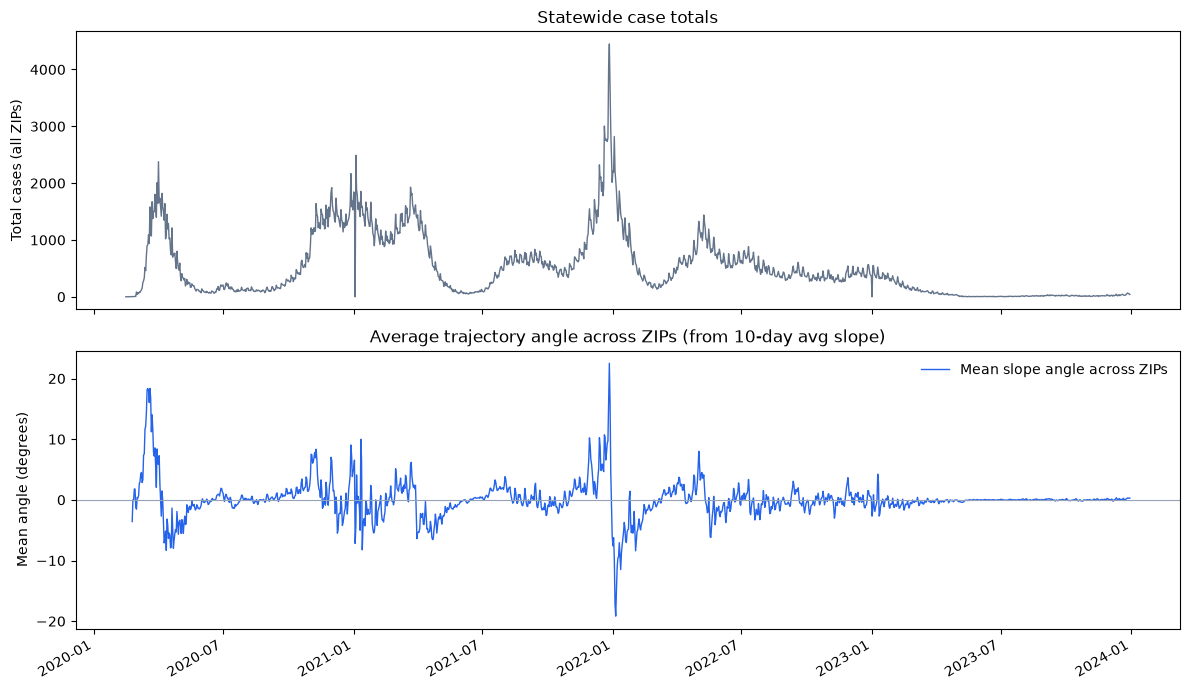

,date,total_cases,mean_avg_slope,mean_avg_slope_angle_deg,median_avg_slope_angle_deg,share_positive_angle
1410,2023-12-26,57,0.004523,0.226796,0.0,0.094298
1411,2023-12-27,67,0.006168,0.319739,0.0,0.120614
1412,2023-12-28,54,0.004934,0.278303,0.0,0.127193
1413,2023-12-29,54,0.004386,0.251747,0.0,0.114035
1414,2023-12-30,41,0.005208,0.296244,0.0,0.109649


In [8]:
daily = (
    panel.groupby("date", as_index=False)
    .agg(
        total_cases=("cases_today", "sum"),
        mean_avg_slope=("avg_slope_10d", "mean"),
        mean_avg_slope_angle_deg=("avg_slope_angle_deg", "mean"),
        median_avg_slope_angle_deg=("avg_slope_angle_deg", "median"),
        share_positive_angle=("avg_slope_angle_deg", lambda s: float((s.dropna() > 0).mean()) if s.notna().any() else np.nan),
    )
    .sort_values("date")
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(daily.date, daily.total_cases, color="#64748B", linewidth=1)
axes[0].set_ylabel("Total cases (all ZIPs)")
axes[0].set_title("Statewide case totals")

axes[1].plot(daily.date, daily.mean_avg_slope_angle_deg, color="#2563EB", linewidth=1, label="Mean slope angle across ZIPs")
axes[1].axhline(0, color="#94A3B8", linewidth=0.8)
axes[1].set_ylabel("Mean angle (degrees)")
axes[1].set_title("Average trajectory angle across ZIPs (from 10-day avg slope)")
axes[1].legend(frameon=False)

fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(FIGDIR / "01_statewide_cases_vs_mean_slope.png", dpi=150)
plt.show()

daily.to_csv(OUTPUT / "statewide_daily_cases_and_slopes.csv", index=False)
daily.tail()


## 3. High-case ZIPs: daily cases with slope angle overlaid

For busy places, plot cases (left axis) and the 10-day average slope **angle** (right axis).  
Angle above 0° = climbing; below 0° = falling.

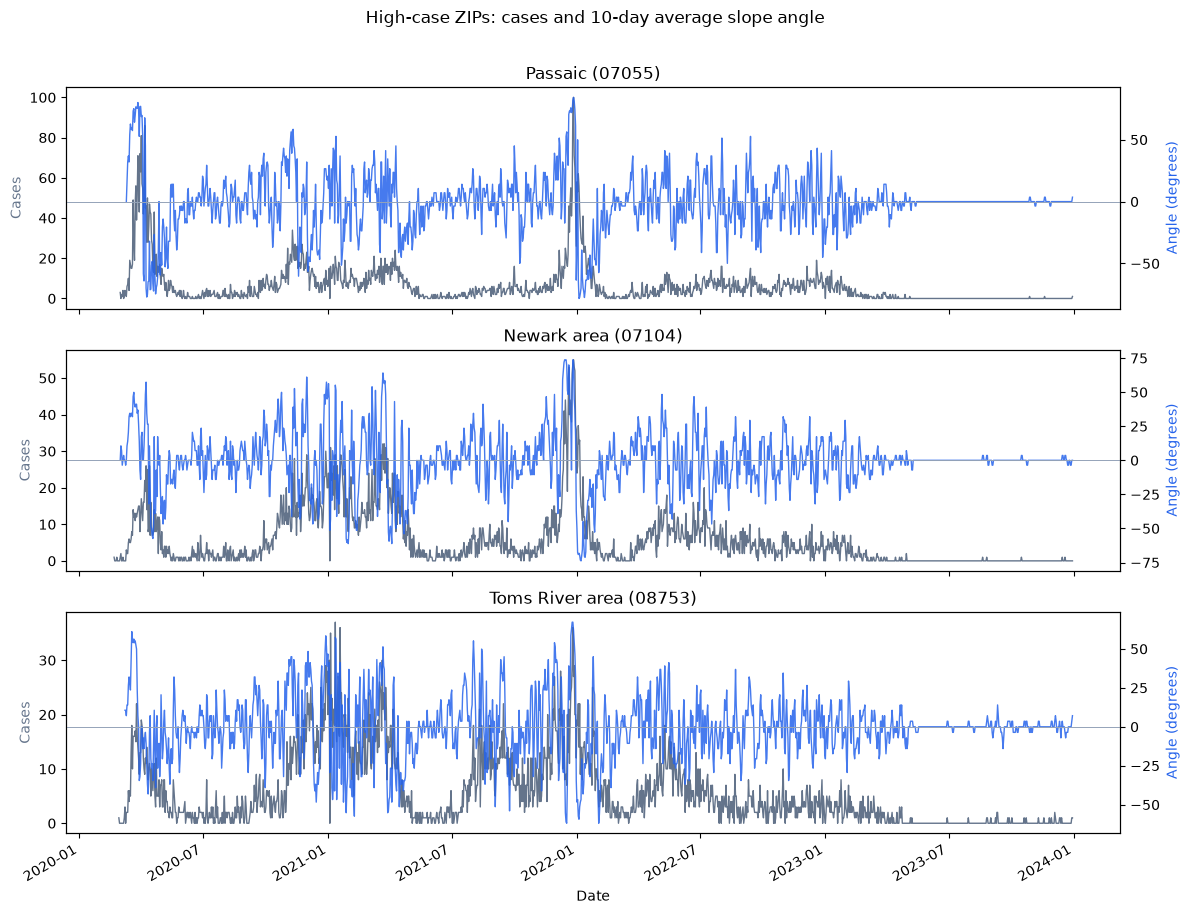

In [9]:
places = {
    "07055": "Passaic",
    "07104": "Newark area",
    "08753": "Toms River area",
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (zipcode, name) in zip(axes, places.items()):
    one = panel.loc[panel.zip.eq(zipcode)].sort_values("date")
    ax.plot(one.date, one.cases_today, color="#64748B", linewidth=1, label="Daily cases")
    ax.set_ylabel("Cases", color="#64748B")
    ax2 = ax.twinx()
    ax2.plot(one.date, one.avg_slope_angle_deg, color="#2563EB", linewidth=1, alpha=0.85, label="slope angle (deg)")
    ax2.axhline(0, color="#94A3B8", linewidth=0.7)
    ax2.set_ylabel("Angle (degrees)", color="#2563EB")
    ax.set_title(f"{name} ({zipcode})")

axes[-1].set_xlabel("Date")
fig.suptitle("High-case ZIPs: cases and 10-day average slope angle", y=1.01)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(FIGDIR / "02_high_case_zips_cases_and_slope.png", dpi=150)
plt.show()


## 4. Zoom on a big wave (Omicron window)

Same idea with slope **angle**, limited to Dec 2021 – Feb 2022.

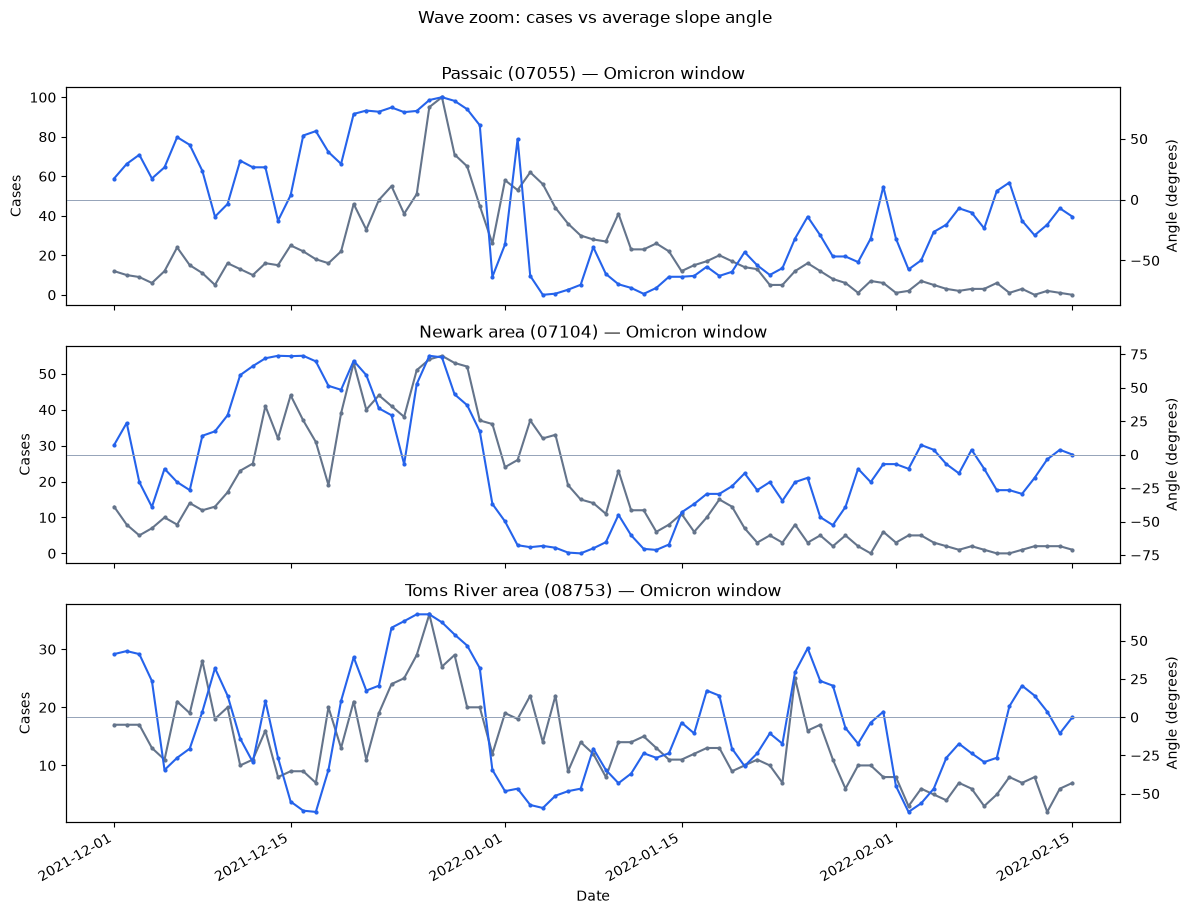

In [10]:
wave = panel.loc[panel.date.between("2021-12-01", "2022-02-15")].copy()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (zipcode, name) in zip(axes, places.items()):
    one = wave.loc[wave.zip.eq(zipcode)].sort_values("date")
    ax.plot(one.date, one.cases_today, color="#64748B", marker="o", markersize=2, label="Daily cases")
    ax2 = ax.twinx()
    ax2.plot(one.date, one.avg_slope_angle_deg, color="#2563EB", marker="o", markersize=2, label="slope angle (deg)")
    ax2.axhline(0, color="#94A3B8", linewidth=0.7)
    ax.set_ylabel("Cases")
    ax2.set_ylabel("Angle (degrees)")
    ax.set_title(f"{name} ({zipcode}) — Omicron window")

axes[-1].set_xlabel("Date")
fig.suptitle("Wave zoom: cases vs average slope angle", y=1.01)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(FIGDIR / "03_omicron_zoom_cases_and_slope.png", dpi=150)
plt.show()


## 5. Cases vs slope angle scatter (same day)

Same cloud as before, but **Y is the angle in degrees** instead of raw slope. Easier to say “about 10° climb” than “0.18 cases/day.”

### How to read

- **X** = cases that day (right = busier)
- **Y** = 10-day average slope angle (up = climbing, down = falling, 0° = flat)
- Thick blob near (0, 0°): quiet, flat days
- High and right: busy and steeply climbing
- Low and right: busy but falling

Still **not** a timeline — each dot is one ZIP-day.


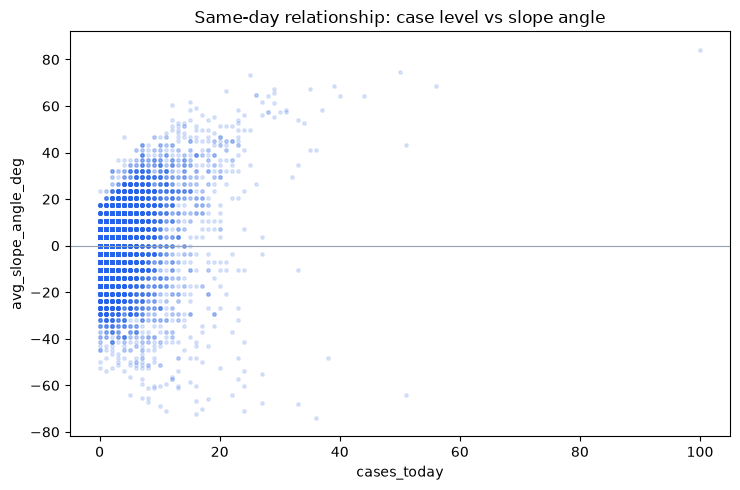

Correlation(cases_today, avg_slope_angle_deg) = 0.286


In [11]:
sample = panel.dropna(subset=["avg_slope_angle_deg"]).sample(
    n=min(40000, panel["avg_slope_angle_deg"].notna().sum()), random_state=42
)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(sample.cases_today, sample.avg_slope_angle_deg, s=6, alpha=0.15, color="#2563EB")
ax.axhline(0, color="#94A3B8", linewidth=0.8)
ax.set_xlabel("cases_today")
ax.set_ylabel("avg_slope_angle_deg")
ax.set_title("Same-day relationship: case level vs slope angle")
fig.tight_layout()
fig.savefig(FIGDIR / "04_scatter_cases_vs_avg_slope.png", dpi=150)
plt.show()

corr = panel.dropna(subset=["avg_slope_angle_deg"])[["cases_today", "avg_slope_angle_deg"]].corr().iloc[0, 1]
print(f"Correlation(cases_today, avg_slope_angle_deg) = {corr:.3f}")


## 6. Summary table for slides

Scale check for both raw 10-day average slope and its angle in degrees.

In [12]:
summary = panel[["avg_slope_10d", "avg_slope_angle_deg"]].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)
extra = pd.DataFrame({
    "avg_slope_10d": [
        (panel["avg_slope_10d"] > 0).mean(),
        (panel["avg_slope_10d"] > 1).mean(),
        (panel["avg_slope_10d"] > 5).mean(),
        (panel["avg_slope_10d"] > 30).mean(),
    ],
    "avg_slope_angle_deg": [
        (panel["avg_slope_angle_deg"] > 0).mean(),
        (panel["avg_slope_angle_deg"] > 5).mean(),
        (panel["avg_slope_angle_deg"] > 20).mean(),
        (panel["avg_slope_angle_deg"] > 45).mean(),
    ],
}, index=["share_gt_0_or_0deg", "share_gt_1_or_5deg", "share_gt_5_or_20deg", "share_gt_30_or_45deg"])
summary = pd.concat([summary, extra])
summary.to_csv(OUTPUT / "avg_slope_10d_summary.csv")
summary.round(4)


,avg_slope_10d,avg_slope_angle_deg
count,625423.0000,625423.0000
mean,-0.0003,-0.0326
std,0.1914,8.9863
min,-5.8750,-80.3401
50%,0.0000,0.0000
75%,0.0625,3.5763
90%,0.1250,7.1250
95%,0.2500,14.0362
99%,0.5625,29.3578
max,9.8125,84.1810


## 7. Challenges (read this for the mentor discussion)

### 1. Only a few true waves to learn from
Big COVID waves in 2020–2023 are limited (early pandemic, winter waves, Delta, Omicron).  
Daily case forecasting has hundreds of thousands of ZIP-day examples.  
**Outbreak-start detection** has only a handful of major events.  
That makes it hard to train or validate a reliable “early outbreak” classifier.

### 2. Slope is mostly concurrent steepening, not early prophecy
The scatter and ZIP charts show steep average slopes usually when cases are **already high**.  
So trajectory/slope is strong as a **monitoring view** (“the path is steepening now”),  
weak as a claim that we foresaw a quiet-to-outbreak jump weeks ahead.

### 3. Wrong absolute thresholds (e.g. slope > 30)
At ZIP daily scale, average slopes are usually near 0; the 99th percentile is about 0.56.  
A threshold like 30 almost never appears. Any alert rule needs **data-driven cutoffs**, not arbitrary big numbers.

### 4. Angle helps communication, not new information
Converting slope to `arctan` degrees makes slides easier to read, but it is a **rescaling** of the same 10-day average slope. It does not add foresight by itself.

### 5. Short-horizon forecasts only beat persistence a little
Our rolling dynamic panel improves on “tomorrow = today” in some windows, but the lift is modest.  
A slope built from those predictions inherits that same limit: if predicted counts stay near today, predicted trajectories stay near flat.

### 6. Longer horizons (e.g. 14 days) get harder, not easier
Error grows with horizon. Extending from 3-day to 14-day counts usually **reduces** trust in any trajectory/outbreak story built from those forecasts.

### 7. Overlapping slopes are correlated with each other
Windows (1–3), (2–4), (3–5), … share days, so the 10-day average slope is a smoothed version of recent change — close in spirit to velocity / rolling differences.  
It is useful for **display**, but not a totally new information source.

### 8. Zeros and sparse ZIP-days dominate the picture
Many ZIP-days are 0 cases. That creates a thick cloud near the origin in the scatter and can make slopes jumpy when a ZIP goes 0 → 2 → 0.

### 9. ZIP vs statewide scale confusion
Statewide total cases can show large slopes; a single ZIP usually cannot.  
Rules and visuals must state whether they are ZIP-level or statewide.

### 10. Label ambiguity for “outbreak”
Without a fixed definition (e.g. next 14-day mean above a baseline), we cannot score precision/recall for threat alerts.  
Trajectory charts can still be shown; formal outbreak validation needs an agreed label.

### 11. Changing COVID regime
Policy, testing, and variants change over time. That is why we use **rolling training windows** for the model.  
The same issue affects any slope/alert rule: a cutoff that worked in Omicron may fail in a quiet 2023 period.

---

## Short takeaway

- Keep the **rolling dynamic panel** as the forecasting model (1–3 day cases vs persistence).
- Use these trajectory/slope plots as the **visual layer** for the mentor.
- Be explicit about limits: few waves for outbreak training, modest forecast lift, slope = steepness monitor more than early oracle.
